# Task 4 — SMS Spam Detection with Machine Learning

Classify messages as spam or ham. Dataset: UCI SMS Spam Collection (5,574 labelled SMS messages), downloaded on first run. Although the task description says email, this standard SMS corpus is a suitable spam/ham NLP benchmark; note this distinction in your submission.

In [9]:
# If needed: %pip install pandas numpy matplotlib seaborn scikit-learn requests
import re,io,zipfile,requests
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,ConfusionMatrixDisplay
RANDOM_STATE=42; sns.set_theme(style='whitegrid')

## 1. Download and load dataset

In [10]:
data_dir=Path('data'); data_dir.mkdir(exist_ok=True); data_file=data_dir/'SMSSpamCollection'
url='https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
if not data_file.exists():
 response=requests.get(url,timeout=60); response.raise_for_status()
 with zipfile.ZipFile(io.BytesIO(response.content)) as z: name=next(n for n in z.namelist() if n.endswith('SMSSpamCollection')); data_file.write_bytes(z.read(name))
df=pd.read_csv(data_file,sep='\t',header=None,names=['label','message'],encoding='utf-8')
print('Shape:',df.shape); display(df.head())

Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Class distribution and data quality

label      object
message    object
dtype: object
Nulls:
 label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


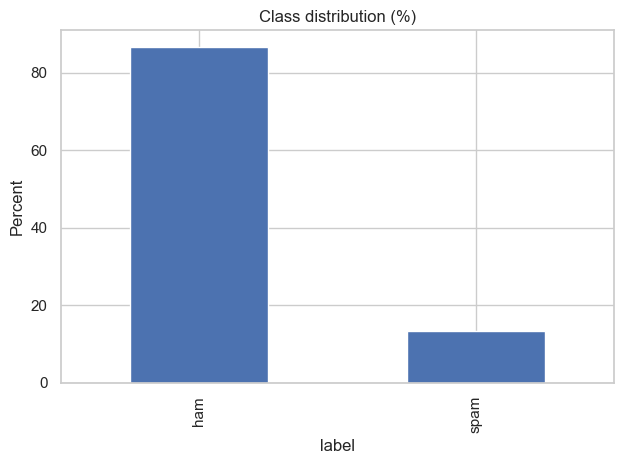

In [11]:
print(df.dtypes); print('Nulls:\n',df.isna().sum()); print('Duplicates:',df.duplicated().sum()); print(df.label.value_counts())
(df.label.value_counts(normalize=True)*100).plot(kind='bar',title='Class distribution (%)',ylabel='Percent'); plt.tight_layout(); plt.show()

**Observation:** Ham messages substantially outnumber spam in this dataset. Accuracy alone can hide missed spam, so we explicitly evaluate spam precision, recall, and F1.

## 3. Text preprocessing and TF-IDF

We lowercase, remove URLs, punctuation and digits, then collapse whitespace. TF-IDF (term frequency–inverse document frequency) weights terms by how often they occur in a message while down-weighting terms common across many messages. The vectorizer is fitted only on training data inside each pipeline. English stopwords are removed by the vectorizer.

In [12]:
def clean_text(text):
 text=str(text).lower(); text=re.sub(r'http\S+|www\.\S+',' ',text); text=re.sub(r'[^a-z\s]',' ',text); return re.sub(r'\s+',' ',text).strip()
df['clean_message']=df.message.map(clean_text); display(df[['message','clean_message','label']].head())

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,ham
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...,spam
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,ham


## 4. Split and train two classifiers

In [13]:
X=df.clean_message; y=df.label
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE,stratify=y)
models={'Multinomial Naive Bayes':Pipeline([('tfidf',TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=2,max_df=.98,sublinear_tf=True)),('model',MultinomialNB(alpha=.5))]),'Logistic Regression':Pipeline([('tfidf',TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=2,max_df=.98,sublinear_tf=True)),('model',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))])}
fitted={}; rows=[]
for name,model in models.items():
 model.fit(X_train,y_train); pred=model.predict(X_test); fitted[name]=model
 rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Spam precision':precision_score(y_test,pred,pos_label='spam',zero_division=0),'Spam recall':recall_score(y_test,pred,pos_label='spam',zero_division=0),'Spam F1':f1_score(y_test,pred,pos_label='spam',zero_division=0)})
results=pd.DataFrame(rows).sort_values(['Spam F1','Spam recall'],ascending=False); display(results)

,Model,Accuracy,Spam precision,Spam recall,Spam F1
1,Logistic Regression,0.973991,0.879747,0.932886,0.905537
0,Multinomial Naive Bayes,0.973094,1.000000,0.798658,0.888060


## 5. Evaluation and confusion matrices


=== Multinomial Naive Bayes ===
Accuracy: 0.9730941704035875
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.80      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



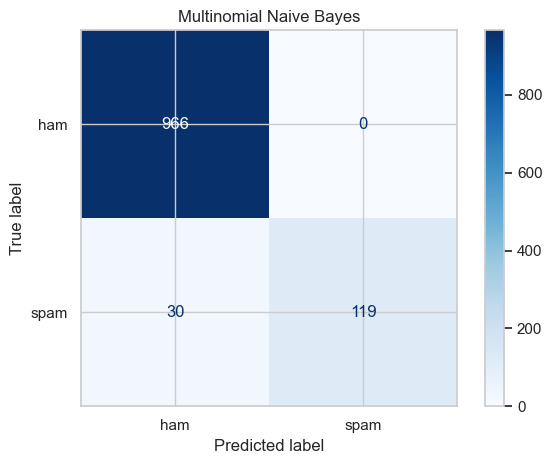


=== Logistic Regression ===
Accuracy: 0.9739910313901345
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       966
        spam       0.88      0.93      0.91       149

    accuracy                           0.97      1115
   macro avg       0.93      0.96      0.95      1115
weighted avg       0.97      0.97      0.97      1115



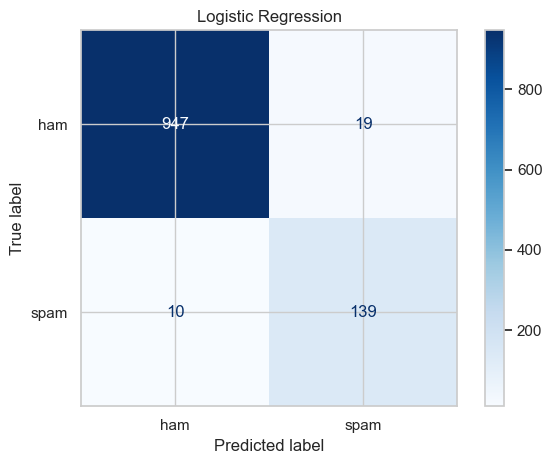

In [14]:
for name,model in fitted.items():
 pred=model.predict(X_test); print('\n===',name,'==='); print('Accuracy:',accuracy_score(y_test,pred)); print(classification_report(y_test,pred,labels=['ham','spam'],zero_division=0))
 ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=['ham','spam'],display_labels=['ham','spam'],cmap='Blues'); plt.title(name); plt.tight_layout(); plt.show()

### Why is spam recall particularly important?

Spam recall = TP / (TP + FN), where FN is spam incorrectly classified as ham. High recall means fewer spam messages slip into the legitimate inbox. But very high recall can come at the cost of lower precision, meaning legitimate messages may be flagged. A real deployment should tune the decision threshold to balance these costs.

## 6. Select best model and inspect spam-associated terms

Selected: Logistic Regression (highest spam F1; recall tie-breaker)
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       966
        spam       0.88      0.93      0.91       149

    accuracy                           0.97      1115
   macro avg       0.93      0.96      0.95      1115
weighted avg       0.97      0.97      0.97      1115



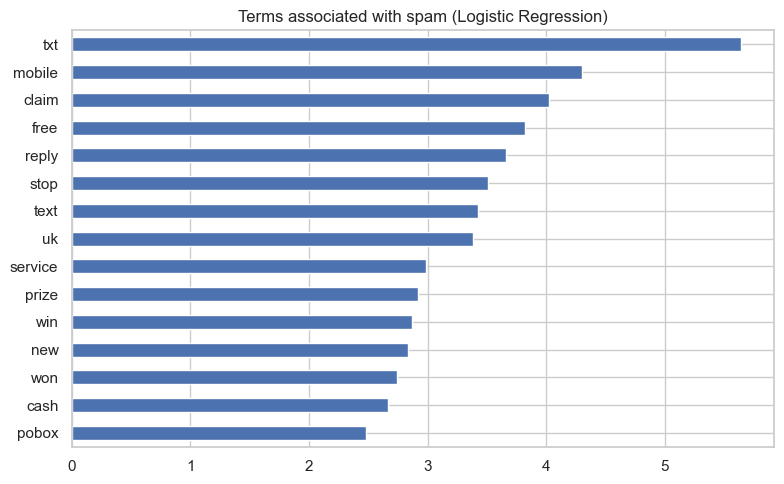

In [15]:
best_name=results.iloc[0]['Model']; best_model=fitted[best_name]; print('Selected:',best_name,'(highest spam F1; recall tie-breaker)')
print(classification_report(y_test,best_model.predict(X_test),labels=['ham','spam'],zero_division=0))
lr=fitted['Logistic Regression']; vec=lr.named_steps['tfidf']; clf=lr.named_steps['model']; terms=np.array(vec.get_feature_names_out()); spam_idx=list(clf.classes_).index('spam'); weights=clf.coef_[0] if spam_idx==1 else -clf.coef_[0]; top=np.argsort(weights)[-15:]
pd.Series(weights[top],index=terms[top]).sort_values().plot(kind='barh',figsize=(8,5),title='Terms associated with spam (Logistic Regression)'); plt.tight_layout(); plt.show()

## 7. Predict a custom message

In [17]:
def predict_message(message):
 cleaned=clean_text(message); label=best_model.predict([cleaned])[0]; probs=dict(zip(best_model.classes_,best_model.predict_proba([cleaned])[0])) if hasattr(best_model,'predict_proba') else {}; return label,probs
sample='Congratulations! You have won a free prize. Call now to claim.'
print(predict_message(sample))

('spam', {'ham': np.float64(0.017454906616283128), 'spam': np.float64(0.9825450933837169)})


## 8. Conclusion and limitations

Compare spam precision, recall and F1 alongside accuracy. The selected model is chosen by spam F1 with recall as tie-breaker. The corpus contains SMS, not full email messages; modern spam changes over time. A production system needs fresh representative validation data, threshold tuning and monitoring.